# Simulations: Seasonal Random Walk

This notebook runs a Monte Carlo simulation on a Seasonal Random Walk process ($s=7$):
$$y_t = y_{t-7} + \varepsilon_t, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2), \quad y_0, \dots, y_6 \sim \mathcal{N}(0, \sigma^2)$$
evaluated across multiple forecast horizons $h \in [1, 3, 7, 14, 30]$ over 100 Monte Carlo replications.

### Experimental Design
1. **Seasonal Naive**: $\hat{y}_{t+h \mid t} = y_{t+h-7 \lceil h/7 \rceil}$ (theoretically optimal Bayes conditional expectation for seasonal random walks).
2. **SARIMA(1,0,1)(0,1,0)_7**: seasonal unit root model testing parameter cancellation $\phi_1 \approx -\theta_1$ on seasonal first differences $\Delta_7 y_t$.
3. **Random Forest on Levels**: recursive non-linear regression on raw levels using Careggi-style lags ($X_t = [y_{t-1}, y_{t-2}, y_{t-7}, y_{t-14}]$), testing the bounded extrapolation failure under seasonal non-stationarity.
4. **Random Forest on Seasonal Differences ($d=7$) with Inversion**: recursive non-linear regression on stationary seasonal differences ($\Delta_7 y_t$) with difference inversion (`diffinv`: $\hat{y}_{t+h \mid t} = y_{t+h-7\lceil h/7\rceil} + \sum \widehat{\Delta_7 y}$), testing whether seasonal differencing rescues trees and tracks the Seasonal Naive baseline.

## 1. Setup and Parameters

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Universal modular simulation engine and DGPs
from src.simulations import (
    generate_seasonal_rw,
    model_naive_multistep,
    model_sarima_srw_multistep,
    model_rf_levels_multistep,
    model_rf_diff_multistep,
    run_simulation_multistep,
)

FIG_DIR = Path("figures/simulations")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("../Results/Simulations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Simulation parameters calibrated to Careggi dataset dimensions
N_SAMPLES = 2542
N_TEST = 364
N_SIM = 100
SIGMA = 1.0
PERIOD = 7
BASE_SEED = 42
HORIZONS = [1, 3, 7, 14, 30]


## 2. Monte Carlo Simulation Execution

In [2]:
print(f"Executing {N_SIM} Monte Carlo replications (T={N_SAMPLES}, Test={N_TEST}, s={PERIOD}) for Seasonal Random Walk across horizons {HORIZONS}...")

models_srw = {
    "snaive": model_naive_multistep(period=PERIOD),
    "sarima101_010": model_sarima_srw_multistep(
        order=(1, 0, 1),
        seasonal_order=(0, 1, 0, PERIOD),
        trend="n",
        maxiter=200,
    ),
    "rf_lvl_seasonal": model_rf_levels_multistep(lags=[1, 2, 7, 14], n_estimators=100),
    "rf_diff_seasonal": model_rf_diff_multistep(lags=[1, 2, 7, 14], d=PERIOD, n_estimators=100),
}

df_results = run_simulation_multistep(
    dgp_fn=generate_seasonal_rw,
    models=models_srw,
    n_sim=N_SIM,
    n_samples=N_SAMPLES,
    n_test=N_TEST,
    horizons=HORIZONS,
    sigma=SIGMA,
    period=PERIOD,
    base_seed=BASE_SEED,
    n_jobs=-1,
)

csv_path = RESULTS_DIR / "srw_results_100.csv"
df_results.to_csv(csv_path, index=False)
print(f"Replication results successfully saved to: {csv_path}")


Executing 100 Monte Carlo replications (T=2542, Test=364, s=7) for Seasonal Random Walk across horizons [1, 3, 7, 14, 30]...


Replication results successfully saved to: ../Results/Simulations/srw_results_100.csv


## 3. Summary Statistics and Model Comparison

In [3]:
models_list = [
    ("Seasonal Naive (s=7)", "snaive"),
    ("SARIMA(1,0,1)(0,1,0)_7", "sarima101_010"),
    ("RF Levels [1, 2, 7, 14]", "rf_lvl_seasonal"),
    ("RF Diff [1, 2, 7, 14] (d=7)", "rf_diff_seasonal"),
]

# 1. Performance Summary Table across all horizons
summary_rows = []
for h in HORIZONS:
    snaive_rmse_mean = df_results[f"rmse_snaive_h{h}"].mean()
    for label, m_key in models_list:
        r_col = f"rmse_{m_key}_h{h}"
        m_col = f"mae_{m_key}_h{h}"
        rmse_mean = df_results[r_col].mean()
        mae_mean = df_results[m_col].mean()
        penalty = ((rmse_mean - snaive_rmse_mean) / snaive_rmse_mean) * 100
        summary_rows.append({
            "Horizon": f"h={h}",
            "Model": label,
            "RMSE Mean": rmse_mean,
            "RMSE Std": df_results[r_col].std(),
            "MAE Mean": mae_mean,
            "MAE Std": df_results[m_col].std(),
            "Penalty vs S.Naive (%)": penalty,
        })

df_summary = pd.DataFrame(summary_rows)
print("=== Performance Summary across 100 Seasonal Random Walk Replications ===")
display(df_summary.round(4))

# Pivot table for clean RMSE comparison
pivot_rmse = df_summary.pivot(index="Model", columns="Horizon", values="RMSE Mean")[
    [f"h={h}" for h in HORIZONS]
]
print("\n=== Out-of-Sample Mean RMSE across Forecast Horizons ===")
display(pivot_rmse.round(4))

# 2. Win Rates relative to Seasonal Naive Baseline (RMSE) at h=1, h=7, h=30
print("\n=== Win Rates relative to Seasonal Naive Baseline (RMSE) ===")
for h in [1, 7, 30]:
    print(f"\n--- Horizon h={h} ---")
    for label, m_key in models_list:
        if m_key != "snaive":
            win_rate = (df_results[f"rmse_{m_key}_h{h}"] < df_results[f"rmse_snaive_h{h}"]).mean() * 100
            print(f"Win Rate: {label} beats Seasonal Naive in {win_rate:.1f}% of replications.")

# 3. SARIMA(1,0,1)(0,1,0)_7 Parameter Estimates and Cancellation Table on Delta_7 y
df_results["phi_plus_theta"] = df_results["phi_1"] + df_results["theta_1"]
params_df = df_results[["phi_1", "theta_1", "phi_plus_theta"]].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]
params_df.index = ["phi_1 (AR)", "theta_1 (MA)", "phi_1 + theta_1 (Sum)"]
print("\n=== SARIMA(1,0,1)(0,1,0)_7 Parameter Cancellation Analysis on Delta_7 y ===")
display(params_df.round(4))

t_stat, p_val = stats.ttest_1samp(df_results["phi_plus_theta"].dropna(), 0.0)
print(f"Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = {t_stat:.3f}, p-value = {p_val:.4f}")

print(f"\nMean Out-of-Bounds Rate (Test obs outside Train [min, max]): {df_results['oob_rate'].mean() * 100:.1f}%")


=== Performance Summary across 100 Seasonal Random Walk Replications ===


,Horizon,Model,RMSE Mean,RMSE Std,MAE Mean,MAE Std,Penalty vs S.Naive (%)
0,h=1,Seasonal Naive (s=7),0.9963,0.0385,0.7962,0.0341,0.0000
1,h=1,"SARIMA(1,0,1)(0,1,0)_7",0.9967,0.0384,0.7965,0.0339,0.0379
2,h=1,"RF Levels [1, 2, 7, 14]",1.6999,0.7991,1.1878,0.3762,70.6169
3,h=1,"RF Diff [1, 2, 7, 14] (d=7)",1.0345,0.0373,0.8275,0.0335,3.8286
4,h=3,Seasonal Naive (s=7),0.9963,0.0385,0.7962,0.0341,0.0000
5,h=3,"SARIMA(1,0,1)(0,1,0)_7",0.9965,0.0385,0.7961,0.0340,0.0158
6,h=3,"RF Levels [1, 2, 7, 14]",1.6986,0.7960,1.1867,0.3746,70.4857
7,h=3,"RF Diff [1, 2, 7, 14] (d=7)",1.0306,0.0399,0.8237,0.0363,3.4427
8,h=7,Seasonal Naive (s=7),0.9963,0.0385,0.7962,0.0341,0.0000
9,h=7,"SARIMA(1,0,1)(0,1,0)_7",0.9965,0.0386,0.7962,0.0341,0.0111



=== Out-of-Sample Mean RMSE across Forecast Horizons ===


Horizon,h=1,h=3,h=7,h=14,h=30
Model,,,,,
"RF Diff [1, 2, 7, 14] (d=7)",1.0345,1.0306,1.0304,1.4593,2.3130
"RF Levels [1, 2, 7, 14]",1.6999,1.6986,1.6986,2.1098,2.8792
"SARIMA(1,0,1)(0,1,0)_7",0.9967,0.9965,0.9965,1.4092,2.2367
Seasonal Naive (s=7),0.9963,0.9963,0.9963,1.4092,2.2364



=== Win Rates relative to Seasonal Naive Baseline (RMSE) ===

--- Horizon h=1 ---
Win Rate: SARIMA(1,0,1)(0,1,0)_7 beats Seasonal Naive in 38.0% of replications.
Win Rate: RF Levels [1, 2, 7, 14] beats Seasonal Naive in 0.0% of replications.
Win Rate: RF Diff [1, 2, 7, 14] (d=7) beats Seasonal Naive in 0.0% of replications.

--- Horizon h=7 ---
Win Rate: SARIMA(1,0,1)(0,1,0)_7 beats Seasonal Naive in 32.0% of replications.
Win Rate: RF Levels [1, 2, 7, 14] beats Seasonal Naive in 0.0% of replications.
Win Rate: RF Diff [1, 2, 7, 14] (d=7) beats Seasonal Naive in 1.0% of replications.

--- Horizon h=30 ---
Win Rate: SARIMA(1,0,1)(0,1,0)_7 beats Seasonal Naive in 44.0% of replications.
Win Rate: RF Levels [1, 2, 7, 14] beats Seasonal Naive in 0.0% of replications.
Win Rate: RF Diff [1, 2, 7, 14] (d=7) beats Seasonal Naive in 9.0% of replications.

=== SARIMA(1,0,1)(0,1,0)_7 Parameter Cancellation Analysis on Delta_7 y ===


,mean,std,min,25%,50%,75%,max
phi_1 (AR),0.0833,0.5743,-0.9821,-0.3846,0.0055,0.6602,0.9955
theta_1 (MA),-0.0838,0.5785,-0.9985,-0.6846,-0.0018,0.4037,0.9775
phi_1 + theta_1 (Sum),-0.0005,0.0233,-0.0487,-0.0187,-0.0001,0.0196,0.0480


Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = -0.219, p-value = 0.8269

Mean Out-of-Bounds Rate (Test obs outside Train [min, max]): 6.8%


## 4. Visualizations: Seasonal Persistence & Multi-Horizon RMSE

<>:69: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:87: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:69: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:87: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/14/jyl_8skx0p95sd4xm11wggc00000gn/T/ipykernel_28878/1166665341.py:69: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  ax2.set_title("Seasonal Random Walk: Multi-Horizon Forecasting Accuracy across Horizons $h \in [1, 3, 7, 14, 30]$", pad=12)
/var/folders/14/jyl_8skx0p95

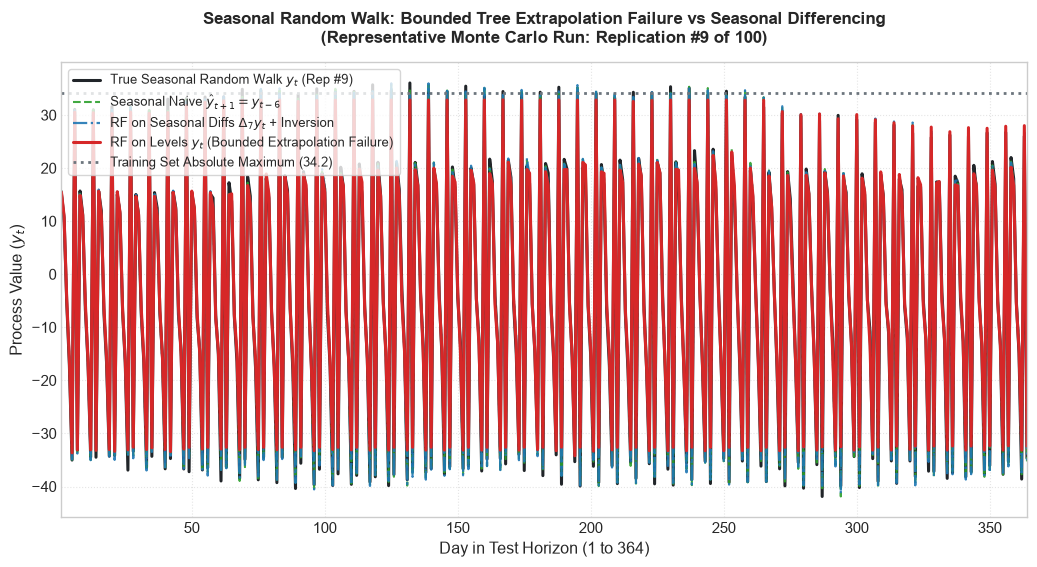

Saved: figures/simulations/srw_seasonal_persistence.png


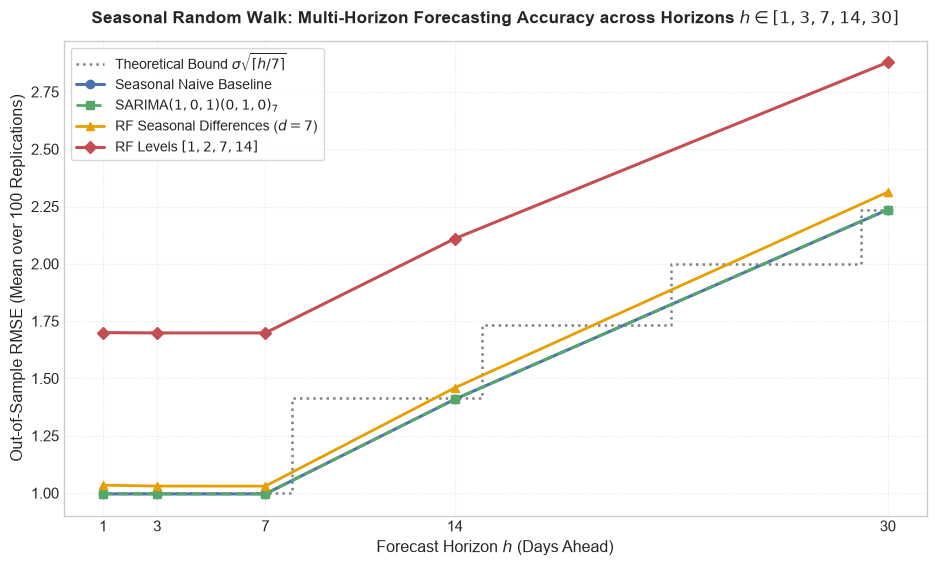

Saved: figures/simulations/srw_multistep_rmse.png


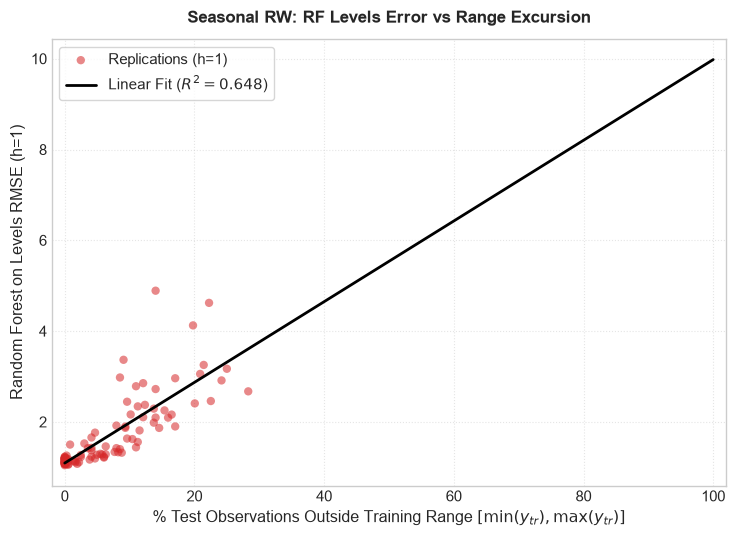

Saved: figures/simulations/srw_oob_scatter.png


In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "figure.titlesize": 13,
    "grid.alpha": 0.5,
    "grid.linestyle": ":",
})

# 1. Figure 1: SRW Visual Bounded Extrapolation Failure (Representative Single Run)
fig1, ax1 = plt.subplots(figsize=(10.5, 5.8))
best_rep = int(df_results["oob_rate"].argmax())
seed_srw = BASE_SEED + best_rep
y_srw = generate_seasonal_rw(n_samples=N_SAMPLES, period=PERIOD, sigma=SIGMA, seed=seed_srw)
n_tr = N_SAMPLES - N_TEST
y_tr = y_srw.iloc[:n_tr]
y_te = y_srw.iloc[n_tr:]
days = np.arange(1, len(y_te) + 1)
max_tr = y_tr.max()

pred_snaive = y_srw.shift(7).iloc[-N_TEST:].to_numpy()
pred_rflvl, _ = model_rf_levels_multistep(lags=[1, 2, 7, 14], n_estimators=100)(y_tr, y_srw, N_TEST, seed_srw, [1])
pred_rfdiff, _ = model_rf_diff_multistep(lags=[1, 2, 7, 14], d=PERIOD, n_estimators=100)(y_tr, y_srw, N_TEST, seed_srw, [1])

ax1.plot(days, y_te.to_numpy(), color="#212529", linewidth=2.2, label=f"True Seasonal Random Walk $y_t$ (Rep #{best_rep})")
ax1.plot(days, pred_snaive, color="#2ca02c", linestyle="--", linewidth=1.5, alpha=0.9, label=r"Seasonal Naive $\hat{y}_{t+1}=y_{t-6}$")
ax1.plot(days, pred_rfdiff[1], color="#1f77b4", linestyle="-.", linewidth=1.6, alpha=0.9, label=r"RF on Seasonal Diffs $\Delta_7 y_t$ + Inversion")
ax1.plot(days, pred_rflvl[1], color="#d62728", linewidth=2.2, label=r"RF on Levels $y_t$ (Bounded Extrapolation Failure)")

ax1.axhline(max_tr, color="#6c757d", linestyle=":", linewidth=2, label=f"Training Set Absolute Maximum ({max_tr:.1f})")

ax1.set_xlabel("Day in Test Horizon (1 to 364)")
ax1.set_ylabel("Process Value ($y_t$)")
ax1.set_title(f"Seasonal Random Walk: Bounded Tree Extrapolation Failure vs Seasonal Differencing\n(Representative Monte Carlo Run: Replication #{best_rep} of {N_SIM})", pad=14)
ax1.legend(loc="upper left", frameon=True, fontsize=9.5)
ax1.set_xlim(1, N_TEST)

plt.tight_layout()
fig1_path = FIG_DIR / "srw_seasonal_persistence.png"
fig1.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

# 2. Figure 2: Multi-Horizon Step Function RMSE Evolution
fig2, ax2 = plt.subplots(figsize=(9.5, 5.8))
h_vals = HORIZONS
snaive_means = [df_results[f"rmse_snaive_h{h}"].mean() for h in h_vals]
sarima_means = [df_results[f"rmse_sarima101_010_h{h}"].mean() for h in h_vals]
rf_diff_means = [df_results[f"rmse_rf_diff_seasonal_h{h}"].mean() for h in h_vals]
rf_lvl_means = [df_results[f"rmse_rf_lvl_seasonal_h{h}"].mean() for h in h_vals]

# Theoretical step curve sigma * sqrt(ceil(h/7))
h_dense = np.arange(1, 31)
theor_step = [SIGMA * np.sqrt(int(np.ceil(h / 7))) for h in h_dense]
ax2.step(h_dense, theor_step, where="post", color="gray", linestyle=":", linewidth=1.8, label=r"Theoretical Bound $\sigma \sqrt{\lceil h/7 \rceil}$")

ax2.plot(h_vals, snaive_means, marker="o", color="#4C72B0", linewidth=2.2, label="Seasonal Naive Baseline")
ax2.plot(h_vals, sarima_means, marker="s", color="#55A868", linestyle="--", linewidth=2.0, label=r"SARIMA$(1,0,1)(0,1,0)_7$")
ax2.plot(h_vals, rf_diff_means, marker="^", color="#E69F00", linewidth=2.0, label="RF Seasonal Differences ($d=7$)")
ax2.plot(h_vals, rf_lvl_means, marker="D", color="#C44E52", linewidth=2.2, label="RF Levels $[1, 2, 7, 14]$")

ax2.set_xlabel("Forecast Horizon $h$ (Days Ahead)")
ax2.set_ylabel("Out-of-Sample RMSE (Mean over 100 Replications)")
ax2.set_title("Seasonal Random Walk: Multi-Horizon Forecasting Accuracy across Horizons $h \in [1, 3, 7, 14, 30]$", pad=12)
ax2.set_xticks(h_vals)
ax2.legend(loc="upper left", frameon=True, fontsize=10)

plt.tight_layout()
fig2_path = FIG_DIR / "srw_multistep_rmse.png"
fig2.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")

# 3. Figure 3: Scatter Plot OOB Rate vs RF Levels RMSE (h=1)
fig3, ax3 = plt.subplots(figsize=(7.5, 5.5))
oob_pct = df_results["oob_rate"] * 100
rmse_lvl = df_results["rmse_rf_lvl_seasonal_h1"]
ax3.scatter(oob_pct, rmse_lvl, alpha=0.55, color="#d62728", edgecolors="none", s=36, label="Replications (h=1)")
slope, intercept, r_val, p_val, _ = stats.linregress(oob_pct, rmse_lvl)
x_line = np.linspace(0, 100, 100)
ax3.plot(x_line, intercept + slope * x_line, color="black", linewidth=2, label=f"Linear Fit ($R^2 = {r_val**2:.3f}$)")
ax3.set_xlabel("% Test Observations Outside Training Range $[\min(y_{tr}), \max(y_{tr})]$")
ax3.set_ylabel("Random Forest on Levels RMSE (h=1)")
ax3.set_title("Seasonal RW: RF Levels Error vs Range Excursion", pad=12)
ax3.set_xlim(-2, 102)
ax3.legend(loc="upper left", frameon=True)
plt.tight_layout()
fig3_path = FIG_DIR / "srw_oob_scatter.png"
fig3.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved: {fig3_path}")
